# 07 - Object size, image conditions and input resolution

**Questions (guide, experiments 3, 4 and the resolution experiment):**
1. Is detection worse for small objects?
2. How much do blur, brightness, contrast, noise and JPEG compression hurt, and do the best confidence / NMS thresholds change under those conditions?
3. Does a larger input resolution buy enough accuracy to justify its cost?

Same detector (YOLOv8n, COCO weights), same 1,000 images, same ground truth, same evaluator in every row. Only the input changes. Corruptions do not change image geometry, so ground-truth boxes stay valid. Default operating point: confidence 0.25, NMS IoU 0.5. mAP columns use all predictions with confidence >= 0.01.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG = os.path.abspath("../figures"); RES = os.path.abspath("../results")
os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)
VOC = os.path.abspath("../data/VOCdevkit/VOC2007")
import cv2, json
from src.experiments import *
from src.corruptions import CORRUPTIONS
from src.dataset import load_voc_subset
from src.evaluation import Evaluator
ids, gts = load_gts(); _, _, paths = load_voc_subset(VOC, 1000, 0)

## Experiment 3 - object size

Ground-truth objects are split by box area with the COCO limits: small < 32^2 px, medium 32^2 - 96^2, large >= 96^2 (in the original image). For a size group, objects of other sizes are ignored (neither counted as missed nor as correct), and unmatched predictions whose own area falls outside the group are ignored too.

,size,n_gt,precision,recall,ap50_at_conf0_01
0,small,103,0.2415,0.7573,0.6154
1,medium,758,0.6763,0.8021,0.7439
2,large,1561,0.8227,0.8591,0.8636
3,all,2422,0.7105,0.8369,0.8271


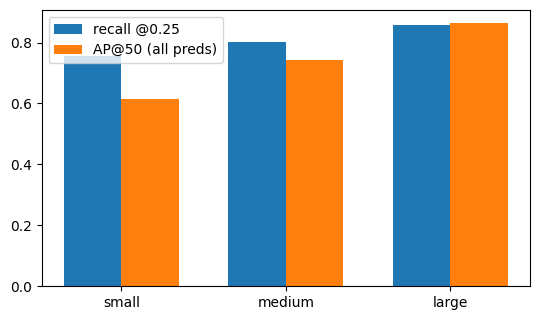

In [2]:
cands = load_candidates("clean_640")
sz = size_study(cands, gts, conf=0.25, nms_iou=0.5); sz.to_csv(f"{RES}/size_results.csv", index=False); display(sz.round(4))
fig, ax = plt.subplots(figsize=(5.5, 3.3)); x = np.arange(3); w = .35
ax.bar(x - w/2, sz.recall[:3], w, label="recall @0.25"); ax.bar(x + w/2, sz.ap50_at_conf0_01[:3], w, label="AP@50 (all preds)")
ax.set_xticks(x); ax.set_xticklabels(sz["size"][:3]); ax.legend(); plt.tight_layout(); plt.savefig(f"{FIG}/size_results.png", dpi=110); plt.show()

## Experiment 4 - image conditions

Parameters are fixed in `src/corruptions.py`: Gaussian blur sigma 3 px; brightness x0.5 and x1.6; contrast x0.4 around the image mean; Gaussian noise sigma 25 (on 0-255); JPEG quality 10. One image under every condition:

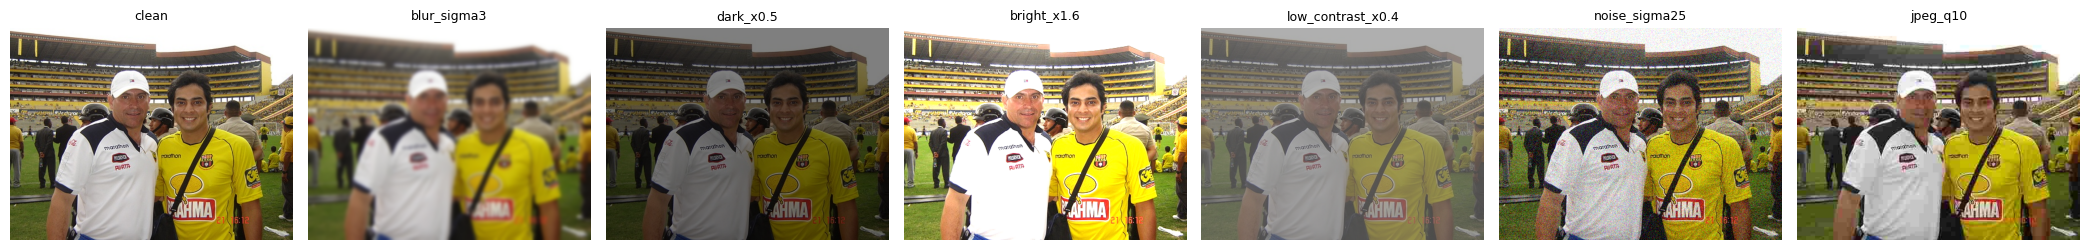

In [3]:
i = ids[7]; im0 = cv2.imread(paths[i]); names = ["clean", "blur_sigma3", "dark_x0.5", "bright_x1.6", "low_contrast_x0.4", "noise_sigma25", "jpeg_q10"]
fig, axes = plt.subplots(1, 7, figsize=(21, 3.2))
for ax, n in zip(axes, names): ax.imshow(cv2.cvtColor(CORRUPTIONS[n](im0), cv2.COLOR_BGR2RGB)); ax.set_title(n, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/corruption_examples.png", dpi=100); plt.show()

conditions available: ['clean_640', 'blur_sigma3_640', 'dark_x0.5_640', 'bright_x1.6_640', 'low_contrast_x0.4_640', 'noise_sigma25_640', 'jpeg_q10_640']


,condition,precision,recall,f1,dets_per_img,map50,map50_95,d_precision,d_recall,d_map50,d_map50_95
0,clean_640,0.7105,0.8369,0.7685,3.132,0.8271,0.6041,0.0000,0.0000,0.0000,0.0000
1,blur_sigma3_640,0.7269,0.5429,0.6216,1.871,0.5610,0.3652,0.0164,-0.2940,-0.2661,-0.2389
2,dark_x0.5_640,0.7242,0.8328,0.7747,3.045,0.8232,0.5995,0.0138,-0.0041,-0.0039,-0.0046
3,bright_x1.6_640,0.7044,0.8088,0.7530,3.036,0.8031,0.5758,-0.0061,-0.0281,-0.0240,-0.0283
4,low_contrast_x0.4_640,0.7332,0.7841,0.7578,2.815,0.7910,0.5649,0.0227,-0.0528,-0.0361,-0.0392
5,noise_sigma25_640,0.7495,0.5991,0.6659,2.039,0.6114,0.4064,0.0390,-0.2378,-0.2157,-0.1977
6,jpeg_q10_640,0.6026,0.2898,0.3914,1.198,0.2868,0.1673,-0.1079,-0.5471,-0.5403,-0.4368


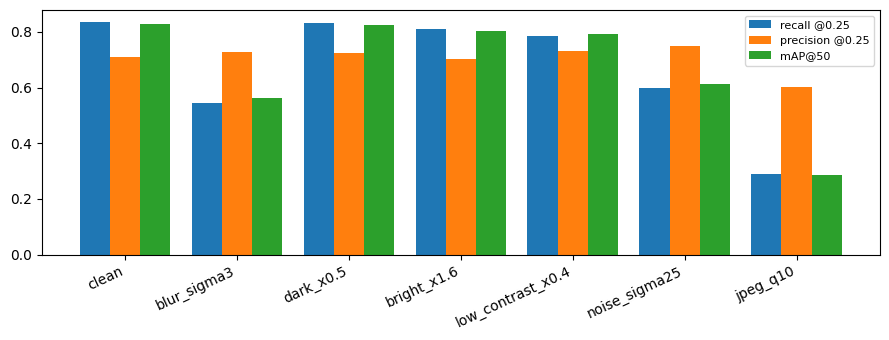

In [4]:
conds = ["clean_640", "blur_sigma3_640", "dark_x0.5_640", "bright_x1.6_640", "low_contrast_x0.4_640", "noise_sigma25_640", "jpeg_q10_640"]
conds = [c_ for c_ in conds if os.path.exists(f"{CACHE}/{c_}.pkl")]; print("conditions available:", conds)
cs = condition_study(conds, gts, conf=0.25, nms_iou=0.5); cs.to_csv(f"{RES}/robustness_results.csv", index=False)
display(cs.round(4))
fig, ax = plt.subplots(figsize=(9, 3.5)); x = np.arange(len(cs)); w = .27
ax.bar(x - w, cs.recall, w, label="recall @0.25"); ax.bar(x, cs.precision, w, label="precision @0.25"); ax.bar(x + w, cs.map50, w, label="mAP@50")
ax.set_xticks(x); ax.set_xticklabels([c_.replace("_640", "") for c_ in cs.condition], rotation=25, ha="right"); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{FIG}/robustness_results.png", dpi=110); plt.show()

### Do the best thresholds change with the image condition?

For each condition: F1 at confidence 0.10 / 0.25 / 0.50 / 0.75 (NMS 0.5), the confidence with the best F1 on a 0.05 grid, and F1 at NMS 0.3 / 0.5 / 0.7 (confidence 0.25).

In [5]:
rows = []
for cn in conds:
    cd = load_candidates(cn); r = dict(condition=cn.replace("_640", ""))
    for t in (0.10, 0.25, 0.50, 0.75): r[f"F1@conf{t}"] = Evaluator(gts, detections(cd, t, 0.5)).metrics(0.5)["f1"]
    grid = {t: Evaluator(gts, detections(cd, t, 0.5)).metrics(0.5)["f1"] for t in np.round(np.arange(0.05, 0.96, 0.05), 2)}
    r["best_conf"] = max(grid, key=grid.get); r["best_F1"] = grid[r["best_conf"]]
    for t in (0.3, 0.5, 0.7): r[f"F1@nms{t}"] = Evaluator(gts, detections(cd, 0.25, t)).metrics(0.5)["f1"]
    rows.append(r)
tg = pd.DataFrame(rows); tg.to_csv(f"{RES}/robustness_threshold_grid.csv", index=False); display(tg.round(3))

,condition,F1@conf0.1,F1@conf0.25,F1@conf0.5,F1@conf0.75,best_conf,best_F1,F1@nms0.3,F1@nms0.5,F1@nms0.7
0,clean,0.645,0.769,0.798,0.651,0.50,0.798,0.769,0.769,0.747
1,blur_sigma3,0.570,0.622,0.543,0.327,0.20,0.623,0.622,0.622,0.611
2,dark_x0.5,0.651,0.775,0.790,0.641,0.40,0.799,0.776,0.775,0.755
3,bright_x1.6,0.631,0.753,0.774,0.612,0.45,0.778,0.752,0.753,0.731
4,low_contrast_x0.4,0.663,0.758,0.763,0.585,0.35,0.777,0.758,0.758,0.738
5,noise_sigma25,0.600,0.666,0.600,0.377,0.25,0.666,0.663,0.666,0.653
6,jpeg_q10,0.375,0.391,0.296,0.124,0.20,0.398,0.390,0.391,0.386


## Experiment 5 - input resolution

Clean images at 320 / 480 / 640 / 800 px (letterboxed square input). Latency was measured separately, one image at a time, one CPU thread, on this machine (`scripts/measure_latency.py`); it is a property of this hardware, not of the model in general.

,input_px,precision,recall,f1,mAP50,mAP50_95,small_recall,forward_ms,pipeline_ms
0,320,0.7625,0.7502,0.7563,0.7923,0.5748,0.3301,55.1500,63.9023
1,480,0.7386,0.8282,0.7808,0.8397,0.6237,0.6019,100.1136,105.5245
2,640,0.7105,0.8369,0.7685,0.8271,0.6041,0.7573,178.1248,186.4639
3,800,0.6791,0.8274,0.7460,0.8021,0.5513,0.7767,266.9738,279.0767


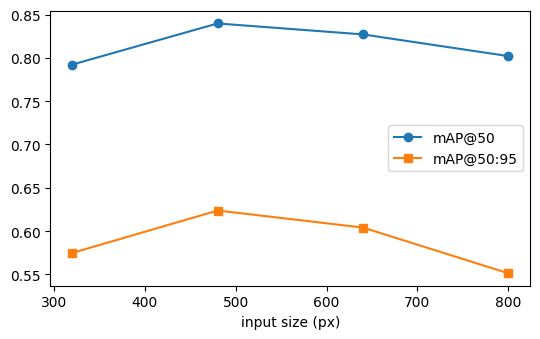

In [6]:
res_names = [n for n in ("clean_320", "clean_480", "clean_640", "clean_800") if os.path.exists(f"{CACHE}/{n}.pkl")]
rows = []
lat = json.load(open(f"{RES}/latency.json")) if os.path.exists(f"{RES}/latency.json") else {}
for n in res_names:
    cd = load_candidates(n); m = Evaluator(gts, detections(cd, 0.25, 0.5)).metrics(0.5); a, b = full_map(cd, gts)
    s = n.split("_")[1]; L = lat.get(s, {})
    rows.append(dict(input_px=int(s), precision=m["precision"], recall=m["recall"], f1=m["f1"], mAP50=a, mAP50_95=b,
                     small_recall=Evaluator(gts, detections(cd, 0.25, 0.5)).metrics(0.5, area_range=(0, 32**2))["recall"],
                     forward_ms=L.get("forward_ms_mean"), pipeline_ms=L.get("pipeline_ms_mean")))
rs = pd.DataFrame(rows); rs.to_csv(f"{RES}/resolution_results.csv", index=False); display(rs.round(4))
fig, ax = plt.subplots(figsize=(5.5, 3.5)); ax.plot(rs.input_px, rs.mAP50, "o-", label="mAP@50"); ax.plot(rs.input_px, rs.mAP50_95, "s-", label="mAP@50:95")
ax.set_xlabel("input size (px)"); ax.legend(); plt.tight_layout(); plt.savefig(f"{FIG}/resolution_results.png", dpi=110); plt.show()

## Observation (computed from the tables above)

In [7]:
b = cs.iloc[0]; w = cs.iloc[1:].sort_values("map50").iloc[0]; bst = cs.iloc[1:].sort_values("map50").iloc[-1]
s = sz.set_index("size"); r0, r1 = rs.iloc[0], rs.iloc[-1]; r640 = rs[rs.input_px == 640].iloc[0]
display(Markdown(f"""
**Size.** Recall at confidence 0.25 is {s.recall['small']:.3f} for small, {s.recall['medium']:.3f} for medium and {s.recall['large']:.3f} for large objects; AP@50 is {s.ap50_at_conf0_01['small']:.3f} / {s.ap50_at_conf0_01['medium']:.3f} / {s.ap50_at_conf0_01['large']:.3f}. Small objects are only {s.n_gt['small']/s.n_gt['all']:.1%} of evaluated objects here ({int(s.n_gt['small'])} objects), so small-object numbers are noisier.

**Conditions.** Change in mAP@50 against clean: {", ".join(f"{r.condition.replace('_640','')} {r.d_map50:+.3f}" for r in cs.iloc[1:].itertuples())}. Clean mAP@50 is {b.map50:.3f}. The most damaging condition tested is **{w.condition.replace('_640','')}** (mAP@50 {w.map50:.3f}, change {w.d_map50:+.3f}; recall {w.recall:.3f} vs {b.recall:.3f}); the mildest is **{bst.condition.replace('_640','')}** (mAP@50 {bst.map50:.3f}, change {bst.d_map50:+.3f}). The strength of each corruption was picked by hand (section 'Experiment 4'), so the ranking compares these specific settings, not corruption types in general.

**Resolution.** mAP@50 by input size: {", ".join(f"{int(r.input_px)} px {r.mAP50:.3f}" for r in rs.itertuples())}. The best mAP@50 is at **{int(rs.loc[rs.mAP50.idxmax(), 'input_px'])} px**, not at the largest input; mAP@50:95 peaks at {int(rs.loc[rs.mAP50_95.idxmax(), 'input_px'])} px. Recall on small objects keeps rising ({", ".join(f"{r.small_recall:.2f}" for r in rs.itertuples())}) but precision falls with size ({", ".join(f"{r.precision:.2f}" for r in rs.itertuples())}), so extra pixels buy small-object recall at the price of more false positives and about {rs.pipeline_ms.iloc[-1] / rs.pipeline_ms.iloc[0]:.1f}x the compute from the smallest to the largest input.

**Thresholds under degraded input.** Best-F1 confidence threshold per condition: {", ".join(f"{r.condition} {r.best_conf:.2f}" for r in tg.itertuples())}. For degraded inputs the best confidence moves down: the fixed default of 0.50 gives F1 {tg.set_index('condition').loc['blur_sigma3', 'F1@conf0.5']:.3f} on blur_sigma3 where the best threshold gives {tg.set_index('condition').loc['blur_sigma3', 'best_F1']:.3f}. The NMS threshold matters much less: across 0.3-0.7 the F1 of any single condition varies by at most {max(tg[['F1@nms0.3','F1@nms0.5','F1@nms0.7']].max(axis=1) - tg[['F1@nms0.3','F1@nms0.5','F1@nms0.7']].min(axis=1)):.3f}.
"""))


**Size.** Recall at confidence 0.25 is 0.757 for small, 0.802 for medium and 0.859 for large objects; AP@50 is 0.615 / 0.744 / 0.864. Small objects are only 4.3% of evaluated objects here (103 objects), so small-object numbers are noisier.

**Conditions.** Change in mAP@50 against clean: blur_sigma3 -0.266, dark_x0.5 -0.004, bright_x1.6 -0.024, low_contrast_x0.4 -0.036, noise_sigma25 -0.216, jpeg_q10 -0.540. Clean mAP@50 is 0.827. The most damaging condition tested is **jpeg_q10** (mAP@50 0.287, change -0.540; recall 0.290 vs 0.837); the mildest is **dark_x0.5** (mAP@50 0.823, change -0.004). The strength of each corruption was picked by hand (section 'Experiment 4'), so the ranking compares these specific settings, not corruption types in general.

**Resolution.** mAP@50 by input size: 320 px 0.792, 480 px 0.840, 640 px 0.827, 800 px 0.802. The best mAP@50 is at **480 px**, not at the largest input; mAP@50:95 peaks at 480 px. Recall on small objects keeps rising (0.33, 0.60, 0.76, 0.78) but precision falls with size (0.76, 0.74, 0.71, 0.68), so extra pixels buy small-object recall at the price of more false positives and about 4.4x the compute from the smallest to the largest input.

**Thresholds under degraded input.** Best-F1 confidence threshold per condition: clean 0.50, blur_sigma3 0.20, dark_x0.5 0.40, bright_x1.6 0.45, low_contrast_x0.4 0.35, noise_sigma25 0.25, jpeg_q10 0.20. For degraded inputs the best confidence moves down: the fixed default of 0.50 gives F1 0.543 on blur_sigma3 where the best threshold gives 0.623. The NMS threshold matters much less: across 0.3-0.7 the F1 of any single condition varies by at most 0.023.


Interpretation limits: one detector, one dataset subset, one severity per corruption, one random seed for the noise. Causes ("blur removes the texture the detector relies on", "small objects have few pixels") are plausible hypotheses that these tables are consistent with or not; they would need further experiments (several severities, several seeds, other detectors) to be established.